In [1]:
import os
import pandas as pd

# --- CONFIGURATION ---
# Point this to wherever your IEMOCAP root folder is
IEMOCAP_ROOT = "D:\Kerja\data_thesis\IEMOCAP_full_release\IEMOCAP_full_release"

# We only care about these four emotions for our thesis
TARGET_EMOTIONS = {"hap", "sad", "ang", "neu"}

# IEMOCAP uses shorthand codes — let's map them to full names
EMOTION_MAP = {
    "hap": "happy",
    "sad": "sad",
    "ang": "angry",
    "neu": "neutral",
    "exc": "excited"  # included temporarily; some papers merge 'exc' into 'happy'
}

records = []  # We'll collect one dict per utterance here

# Loop over all 5 sessions
for session_num in range(1, 6):
    session_dir = os.path.join(IEMOCAP_ROOT, f"Session{session_num}")
    eval_dir = os.path.join(session_dir, "dialog", "EmoEvaluation")
    transcript_dir = os.path.join(session_dir, "dialog", "transcriptions")
    wav_dir = os.path.join(session_dir, "sentences", "wav")

    # Each .txt file in EmoEvaluation corresponds to one dialog
    for label_file in sorted(os.listdir(eval_dir)):
        if not label_file.endswith(".txt"):
            continue

        dialog_id = label_file.replace(".txt", "")
        label_path = os.path.join(eval_dir, label_file)
        transcript_path = os.path.join(transcript_dir, label_file)

        # --- Parse transcriptions into a lookup dict ---
        # Format: "utterance_id: text of what was said"
        transcripts = {}
        if os.path.exists(transcript_path):
            with open(transcript_path, "r", encoding="latin-1", errors="ignore") as f:
                for line in f:
                    line = line.strip()
                    if ":" in line:
                        # Pisahkan ID+Timestamp dengan Teks
                        id_and_time, text = line.split(":", 1)
                        # Ambil hanya ID-nya saja (elemen pertama sebelum spasi/kurung siku)
                        clean_utt_id = id_and_time.split()[0].strip()
                        transcripts[clean_utt_id] = text.strip()

        # --- Parse emotion labels ---
        # We only grab lines that start with '[' (the timestamp lines)
        with open(label_path, "r", encoding="latin-1", errors="ignore") as f:
            for line in f:
                line = line.strip()
                if not line.startswith("["):
                    continue

                parts = line.split()
                # Safety check: a valid label line has at least 4 tokens
                if len(parts) < 4:
                    continue

                utt_id = parts[3]      # e.g., Ses01F_impro01_F000
                emotion = parts[4]     # e.g., "neu"

                # Skip emotions outside our four targets
                # (Note: some researchers merge 'exc' into 'happy' — we skip it for now)
                if emotion not in TARGET_EMOTIONS:
                    continue

                # Build the path to the individual utterance .wav file
                wav_path = os.path.join(wav_dir, dialog_id, f"{utt_id}.wav")

                records.append({
                    "session": session_num,
                    "dialog_id": dialog_id,
                    "utterance_id": utt_id,
                    "emotion": EMOTION_MAP[emotion],
                    "text": transcripts.get(utt_id, ""),  # empty string if not found
                    "wav_path": wav_path,
                    "wav_exists": os.path.exists(wav_path)  # sanity check!
                })

# Build a clean DataFrame
df = pd.DataFrame(records)
print(df.shape)          # How many utterances survived filtering?
print(df["emotion"].value_counts())  # Check class distribution
print(df.head())

(4490, 7)
emotion
neutral    1708
angry      1103
sad        1084
happy       595
Name: count, dtype: int64
   session       dialog_id         utterance_id  emotion  \
0        1  Ses01F_impro01  Ses01F_impro01_F000  neutral   
1        1  Ses01F_impro01  Ses01F_impro01_F001  neutral   
2        1  Ses01F_impro01  Ses01F_impro01_F002  neutral   
3        1  Ses01F_impro01  Ses01F_impro01_F005  neutral   
4        1  Ses01F_impro01  Ses01F_impro01_F012    angry   

                                          text  \
0                                   Excuse me.   
1                                        Yeah.   
2                          Is there a problem?   
3  Well what's the problem?  Let me change it.   
4                       That's out of control.   

                                            wav_path  wav_exists  
0  D:\Kerja\data_thesis\IEMOCAP_full_release\IEMO...        True  
1  D:\Kerja\data_thesis\IEMOCAP_full_release\IEMO...        True  
2  D:\Kerja\data_thesis\IEMOC

In [2]:
# Sort the entire DataFrame by session, dialog, and utterance order
# IEMOCAP utterance IDs end in _M001, _F002, etc.
# The number at the end is the turn index — we extract it for proper sorting

import re

def extract_turn_index(utterance_id):
    """Pull the numeric turn index from the end of an utterance ID.
    e.g., 'Ses01F_impro01_M003' → 3
    """
    match = re.search(r'_[MF](\d+)$', utterance_id)
    return int(match.group(1)) if match else 0

df["turn_index"] = df["utterance_id"].apply(extract_turn_index)

# Sort so utterances appear in the order they were actually spoken
df = df.sort_values(["session", "dialog_id", "turn_index"]).reset_index(drop=True)

# --- Build conversation sequences ---
# Each sequence is one dialog: a list of (utterance_id, emotion, text, wav_path)

sequences = []

for dialog_id, group in df.groupby("dialog_id", sort=False):
    utterances = group[["utterance_id", "emotion", "text", "wav_path"]].to_dict("records")
    
    sequences.append({
        "dialog_id": dialog_id,
        "session": group["session"].iloc[0],
        "utterances": utterances,
        "length": len(utterances),
        "emotion_sequence": [u["emotion"] for u in utterances]  # e.g. ['neutral','angry','angry','sad']
    })

print(f"Total dialogs (sequences): {len(sequences)}")
print(f"Average sequence length: {sum(s['length'] for s in sequences) / len(sequences):.1f}")

# Peek at one sequence to verify it looks right
import pprint
pprint.pprint(sequences[0])

Total dialogs (sequences): 151
Average sequence length: 29.7
{'dialog_id': 'Ses01F_impro01',
 'emotion_sequence': ['neutral',
                      'neutral',
                      'neutral',
                      'neutral',
                      'angry',
                      'angry',
                      'angry',
                      'neutral'],
 'length': 8,
 'session': np.int64(1),
 'utterances': [{'emotion': 'neutral',
                 'text': 'Excuse me.',
                 'utterance_id': 'Ses01F_impro01_F000',
                 'wav_path': 'D:\\Kerja\\data_thesis\\IEMOCAP_full_release\\IEMOCAP_full_release\\Session1\\sentences\\wav\\Ses01F_impro01\\Ses01F_impro01_F000.wav'},
                {'emotion': 'neutral',
                 'text': 'Yeah.',
                 'utterance_id': 'Ses01F_impro01_F001',
                 'wav_path': 'D:\\Kerja\\data_thesis\\IEMOCAP_full_release\\IEMOCAP_full_release\\Session1\\sentences\\wav\\Ses01F_impro01\\Ses01F_impro01_F001.wav'},
            

In [3]:
from collections import defaultdict

# Count how often emotion A is followed by emotion B
transition_counts = defaultdict(lambda: defaultdict(int))

for seq in sequences:
    emotions = seq["emotion_sequence"]
    for i in range(len(emotions) - 1):
        current = emotions[i]
        next_e = emotions[i + 1]
        transition_counts[current][next_e] += 1

# Normalize to probabilities
emotion_labels = ["happy", "sad", "angry", "neutral"]
print("\nEmotion Transition Matrix (rows=current, cols=next):\n")
header = f"{'':>10}" + "".join(f"{e:>10}" for e in emotion_labels)
print(header)

for from_e in emotion_labels:
    total = sum(transition_counts[from_e].values())
    row = f"{from_e:>10}"
    for to_e in emotion_labels:
        prob = transition_counts[from_e][to_e] / total if total > 0 else 0
        row += f"{prob:>10.2f}"
    print(row)


Emotion Transition Matrix (rows=current, cols=next):

               happy       sad     angry   neutral
     happy      0.73      0.08      0.01      0.18
       sad      0.05      0.76      0.05      0.15
     angry      0.00      0.05      0.69      0.25
   neutral      0.07      0.10      0.18      0.66


--- Text Length Statistics ---
count    4490.000000
mean       11.203563
std        10.027140
min         1.000000
25%         4.000000
50%         8.000000
75%        15.000000
max        91.000000
Name: word_count, dtype: float64


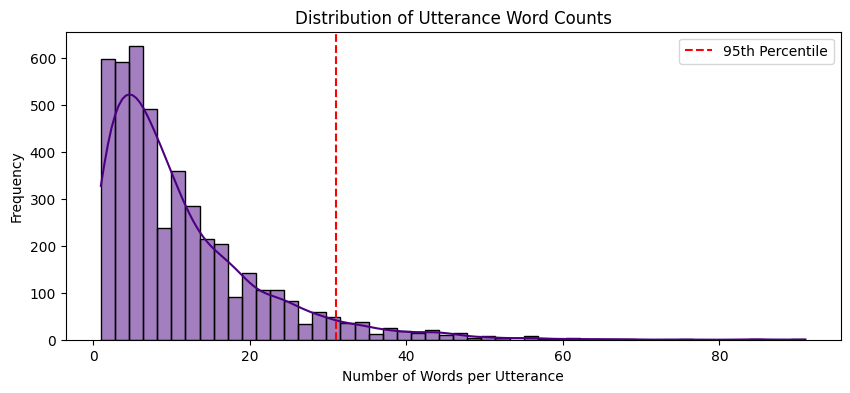

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Calculate word counts for each utterance
df['word_count'] = df['text'].apply(lambda x: len(str(x).split()))

print("--- Text Length Statistics ---")
print(df['word_count'].describe())

# Plot the distribution
plt.figure(figsize=(10, 4))
sns.histplot(df['word_count'], bins=50, kde=True, color='indigo')
plt.title('Distribution of Utterance Word Counts')
plt.xlabel('Number of Words per Utterance')
plt.ylabel('Frequency')
plt.axvline(df['word_count'].quantile(0.95), color='red', linestyle='--', label='95th Percentile')
plt.legend()
plt.show()


--- Audio Duration Statistics (Seconds) ---
count    4490.000000
mean        4.495215
std         3.171135
min         0.730000
25%         2.321250
50%         3.509937
75%         5.699937
max        31.910000
Name: duration_sec, dtype: float64


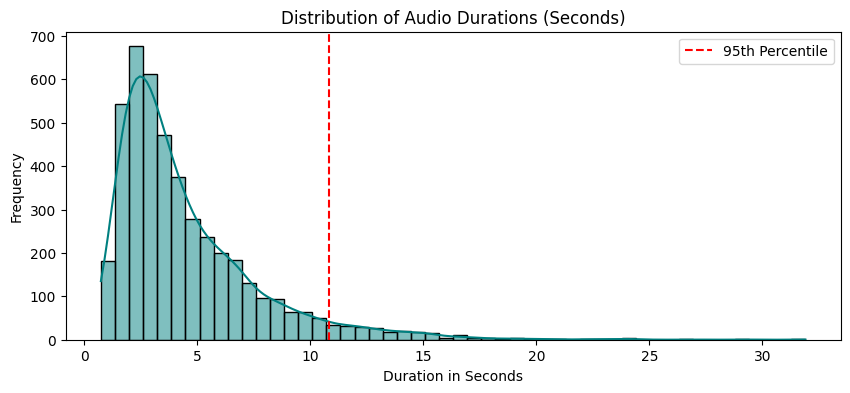

In [5]:
import wave
import contextlib

def get_audio_duration(wav_path):
    try:
        with contextlib.closing(wave.open(wav_path, 'r')) as f:
            frames = f.getnframes()
            rate = f.getframerate()
            return frames / float(rate)
    except Exception as e:
        return 0.0

# Apply the function to get durations
df['duration_sec'] = df['wav_path'].apply(get_audio_duration)

print("\n--- Audio Duration Statistics (Seconds) ---")
print(df['duration_sec'].describe())

# Plot the distribution
plt.figure(figsize=(10, 4))
sns.histplot(df['duration_sec'], bins=50, kde=True, color='teal')
plt.title('Distribution of Audio Durations (Seconds)')
plt.xlabel('Duration in Seconds')
plt.ylabel('Frequency')
plt.axvline(df['duration_sec'].quantile(0.95), color='red', linestyle='--', label='95th Percentile')
plt.legend()
plt.show()

In [6]:
# In IEMOCAP, the speaker gender/ID is the last letter before the turn number
# e.g., Ses01F_impro01_F000 -> Speaker 'F'
def extract_speaker(utterance_id):
    # Split by '_' and look at the last part, the first character is 'F' or 'M'
    return utterance_id.split('_')[-1][0]

df['speaker'] = df['utterance_id'].apply(extract_speaker)

# Let's see how often the speaker changes in our sequences
total_transitions = 0
speaker_changes = 0

for seq in sequences:
    # Get speaker list for this sequence based on our df mapping
    # (Re-extracting quickly for the sequences list)
    speakers = [extract_speaker(u['utterance_id']) for u in seq['utterances']]
    
    for i in range(len(speakers) - 1):
        total_transitions += 1
        if speakers[i] != speakers[i+1]:
            speaker_changes += 1

print("\n--- Speaker Dynamics ---")
print(f"Total Turn Transitions: {total_transitions}")
print(f"Transitions where speaker changes: {speaker_changes}")
print(f"Speaker alternation rate: {(speaker_changes/total_transitions)*100:.1f}%")


--- Speaker Dynamics ---
Total Turn Transitions: 4339
Transitions where speaker changes: 2472
Speaker alternation rate: 57.0%


In [7]:
import librosa
import numpy as np
from sentence_transformers import SentenceTransformer
 
# ─── CONFIGURATION ────────────────────────────────────────────────────────────
 
MAX_AUDIO_SEC = 10
SR = 16000
MAX_AUDIO_SAMPLES = MAX_AUDIO_SEC * SR
 
AUDIO_DIM = 373   # computed below — keep this in sync with extract_audio_features
TEXT_DIM  = 384   # all-MiniLM-L6-v2 output dimension
 
SPEAKER_TO_IDX = {"F": 0, "M": 1}   # integer index for nn.Embedding later
 
# ─── TEXT MODEL (load once, reuse everywhere) ──────────────────────────────────
 
_st_model = SentenceTransformer("all-MiniLM-L6-v2")
 
def get_sentence_embedding(text: str) -> np.ndarray:
    """
    Encodes a single utterance into a 384-dim L2-normalised sentence vector.
    Returns zeros for empty/null input so downstream code never gets NaN.
    """
    text = str(text).strip()
    if not text:
        return np.zeros(TEXT_DIM, dtype=np.float32)
    return _st_model.encode(text, normalize_embeddings=True)   # → (384,)
 
 
# ─── AUDIO FEATURES ───────────────────────────────────────────────────────────
 
def extract_audio_features(wav_path: str) -> np.ndarray:
    """
    Returns a 373-dim float32 vector per utterance.
 
    Feature breakdown:
      40 MFCC mean + 40 std          =  80-dim   (static spectral shape)
      40 MFCC-Δ mean + 40 std        =  80-dim   (rate of spectral change)
      40 MFCC-ΔΔ mean + 40 std       =  80-dim   (acceleration of change)
      64 Mel mean + 64 std           = 128-dim   (fine-grained spectral texture)
      F0 mean, std, max              =   3-dim   (pitch — #1 emotion cue)
      RMS mean, std                  =   2-dim   (energy / loudness)
      ─────────────────────────────────────────
      Total                          = 373-dim
    """
    try:
        y, _ = librosa.load(wav_path, sr=SR, duration=MAX_AUDIO_SEC)
    except Exception as e:
        print(f"[WARN] Could not load {wav_path}: {e}")
        return np.zeros(AUDIO_DIM, dtype=np.float32)
 
    # Pad to exactly MAX_AUDIO_SEC so all vectors have the same length
    if len(y) < MAX_AUDIO_SAMPLES:
        y = np.pad(y, (0, MAX_AUDIO_SAMPLES - len(y)), mode="constant")
 
    def ms(x):
        """Mean + std over the time axis → 1-D vector of length 2 * n_features."""
        return np.concatenate(
            [np.mean(x, axis=-1), np.std(x, axis=-1)]
        ).astype(np.float32)
 
    # Static MFCCs
    mfcc   = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=40)
    mfcc_d = librosa.feature.delta(mfcc)
    mfcc_d2= librosa.feature.delta(mfcc, order=2)
 
    # Mel spectrogram (log-scale)
    mel    = librosa.feature.melspectrogram(y=y, sr=SR, n_mels=64)
    mel_db = librosa.power_to_db(mel, ref=np.max)
 
    # Pitch via pYIN — fmin/fmax tuned for conversational speech
    f0, _, _ = librosa.pyin(y, fmin=librosa.note_to_hz("C2"),
                                fmax=librosa.note_to_hz("C7"), sr=SR)
    f0 = np.nan_to_num(f0, nan=0.0)   # unvoiced frames become 0
 
    # RMS energy
    rms = librosa.feature.rms(y=y)[0]
 
    audio_vec = np.concatenate([
        ms(mfcc),                                           #  80
        ms(mfcc_d),                                         #  80
        ms(mfcc_d2),                                        #  80
        ms(mel_db),                                         # 128
        np.array([np.mean(f0), np.std(f0), np.max(f0)],    #   3
                 dtype=np.float32),
        np.array([np.mean(rms), np.std(rms)],              #   2
                 dtype=np.float32),
    ])
 
    assert audio_vec.shape == (AUDIO_DIM,), \
        f"Audio dim mismatch: expected {AUDIO_DIM}, got {audio_vec.shape[0]}"
 
    return audio_vec
 
 
# ─── FUSED UTTERANCE ──────────────────────────────────────────────────────────
 
def fuse_utterance(wav_path: str, text: str, speaker_id: str) -> dict:
    """
    Extracts and returns all modalities as SEPARATE arrays.
    Do NOT concatenate here — the UpgradedEmotionModel takes them separately
    so that the cross-modal attention layer can operate on each stream.
 
    Returns
    -------
    dict with keys:
      "audio"      : np.ndarray  shape (373,)
      "text"       : np.ndarray  shape (384,)
      "speaker_idx": int         0 = Female, 1 = Male
    """
    audio_vec   = extract_audio_features(wav_path)      # (373,)
    text_vec    = get_sentence_embedding(text)           # (384,)
    speaker_idx = SPEAKER_TO_IDX.get(speaker_id, 0)     # int
 
    return {
        "audio":       audio_vec,
        "text":        text_vec,
        "speaker_idx": speaker_idx,
    }
 
 
# ─── SMOKE TEST ───────────────────────────────────────────────────────────────
 
if __name__ == "__main__":
    # Pull the first utterance from the DataFrame built in Cell 2
    row          = df.iloc[0]
    test_wav     = row["wav_path"]
    test_text    = row["text"]
    test_speaker = row["speaker"]
 
    result = fuse_utterance(test_wav, test_text, test_speaker)
 
    print(f"Utterance : '{test_text}'")
    print(f"Speaker   : '{test_speaker}' → index {result['speaker_idx']}")
    print(f"Audio vec : {result['audio'].shape}   dtype={result['audio'].dtype}")
    print(f"Text vec  : {result['text'].shape}    dtype={result['text'].dtype}")
    print(f"Audio norm: {np.linalg.norm(result['audio']):.4f}  (not normalised — that's fine)")
    print(f"Text norm : {np.linalg.norm(result['text']):.4f}   (should be ~1.0)")
 
    # Verify the sentence transformer is actually encoding semantics
    # (not random noise like the old GloVe mock)
    happy_vec = get_sentence_embedding("I am so happy today!")
    sad_vec   = get_sentence_embedding("I feel really sad and lonely.")
    same_vec  = get_sentence_embedding("I am so happy today!")
    from numpy.linalg import norm
    cos = lambda a, b: np.dot(a, b) / (norm(a) * norm(b))
    print(f"\nSanity check — cosine similarities:")
    print(f"  happy vs sad   : {cos(happy_vec, sad_vec):.4f}  (should be low,  ~0.3–0.5)")
    print(f"  happy vs happy : {cos(happy_vec, same_vec):.4f}  (should be 1.000)")


c:\Users\NicholasAH\.conda\envs\thesis_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\NicholasAH\.conda\envs\thesis_env\Lib\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\NicholasAH\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an admi

Utterance : 'Excuse me.'
Speaker   : 'F' → index 0
Audio vec : (373,)   dtype=float32
Text vec  : (384,)    dtype=float32
Audio norm: 956.6782  (not normalised — that's fine)
Text norm : 1.0000   (should be ~1.0)

Sanity check — cosine similarities:
  happy vs sad   : 0.2600  (should be low,  ~0.3–0.5)
  happy vs happy : 1.0000  (should be 1.000)


In [8]:
import numpy as np

# --- 1. Label Encoding ---
# Neural networks need numbers, not strings. 
emotion_to_int = {"neutral": 0, "happy": 1, "sad": 2, "angry": 3}

# --- 2. Sequence Padding Configuration ---
# Setting max sequence length based on your earlier EDA
MAX_SEQ_LENGTH = 55 
FEATURE_DIM = 382

# --- 3. Sequence Processing Function ---
def process_dialog_batch(dialog_sequences):
    """Converts a list of dialog dictionaries into 3D tensors for the LSTM."""
    num_dialogs = len(dialog_sequences)
    
    # Initialize empty tensors with zeros (this automatically handles our padding!)
    # X shape: (Batch, Sequence_Length, Features)
    X = np.zeros((num_dialogs, MAX_SEQ_LENGTH, FEATURE_DIM), dtype=np.float32)
    
    # y shape: (Batch, Sequence_Length) - holds the integer class labels
    y = np.zeros((num_dialogs, MAX_SEQ_LENGTH), dtype=np.int64) 
    
    # Mask to tell the model which timesteps are real vs padded
    mask = np.zeros((num_dialogs, MAX_SEQ_LENGTH), dtype=np.bool_)
    
    print(f"Processing {num_dialogs} dialogs... extracting audio features takes time!")
    
    for i, seq in enumerate(dialog_sequences):
        utterances = seq['utterances']
        
        # Truncate if a sequence happens to be longer than 55
        seq_len = min(len(utterances), MAX_SEQ_LENGTH)
        
        for t in range(seq_len):
            utt = utterances[t]
            
            # 1. Extract and Fuse Features (using the function from the previous step)
            speaker = extract_speaker(utt['utterance_id']) if 'extract_speaker' in globals() else utt['utterance_id'].split('_')[-1][0]
            features = fuse_utterance(utt['wav_path'], utt['text'], speaker)
            
            # 2. Place into tensor
            X[i, t, :] = features
            
            # 3. Extract Label
            y[i, t] = emotion_to_int[utt['emotion']]
            
            # 4. Update Mask (True means "real data", False means "padding")
            mask[i, t] = True
            
    return X, y, mask

# --- TEST ON A SMALL BATCH ---
# Test on just the first 3 dialogs. 
test_batch = sequences[:3]
X_test, y_test, mask_test = process_dialog_batch(test_batch)

print(f"\n--- Sequence Formatting Complete ---")
print(f"X_test shape (Features): {X_test.shape}") 
print(f"y_test shape (Labels):   {y_test.shape}")
print(f"mask_test shape:         {mask_test.shape}")

Processing 3 dialogs... extracting audio features takes time!


TypeError: float() argument must be a string or a real number, not 'dict'

In [ ]:
import torch
import torch.nn as nn

class UpgradedEmotionModel(nn.Module):
    def __init__(self, audio_dim=256, text_dim=384, hidden_dim=256,
                 num_speakers=10, num_classes=4, dropout=0.3):
        super().__init__()

        # Project audio and text to same dim before fusion
        self.audio_proj = nn.Linear(audio_dim, 256)
        self.text_proj  = nn.Linear(text_dim, 256)

        # Cross-modal attention: audio query attends to text
        self.cross_attn = nn.MultiheadAttention(embed_dim=256, num_heads=4, batch_first=True)

        # Speaker embedding — learnable, injected after fusion
        self.speaker_emb = nn.Embedding(num_speakers, 16)

        # BiLSTM over the fused sequence
        self.bilstm = nn.LSTM(
            input_size=256 + 256 + 16,  # fused audio + text + speaker
            hidden_size=hidden_dim,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=dropout
        )

        # Self-attention over LSTM output (capture long-range sequence deps)
        self.seq_attn = nn.MultiheadAttention(embed_dim=hidden_dim*2, num_heads=4, batch_first=True)

        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim * 2, num_classes)

    def forward(self, audio, text, speaker_ids, mask=None):
        # audio: (B, S, audio_dim), text: (B, S, text_dim)
        B, S, _ = audio.shape

        a = torch.relu(self.audio_proj(audio))   # (B, S, 256)
        t = torch.relu(self.text_proj(text))      # (B, S, 256)

        # Cross-modal: audio queries attend over text keys/values
        a_fused, _ = self.cross_attn(a, t, t)    # (B, S, 256)

        # Inject speaker identity
        spk = self.speaker_emb(speaker_ids)       # (B, S, 16)

        x = torch.cat([a_fused, t, spk], dim=-1)  # (B, S, 256+256+16)
        x = self.dropout(x)

        # BiLSTM — key_padding_mask expects True where PADDED
        lstm_out, _ = self.bilstm(x)              # (B, S, 512)

        # Self-attention over LSTM sequence
        attn_out, _ = self.seq_attn(lstm_out, lstm_out, lstm_out)
        out = self.dropout(attn_out)

        logits = self.classifier(out)             # (B, S, 4)
        return logits
    
best_val_f1 = 0.0
patience_counter = 0
PATIENCE = 10

for epoch in range(EPOCHS):
    # ... training loop as before ...

    # Compute weighted F1 on validation set (not just loss!)
    from sklearn.metrics import f1_score
    val_f1 = f1_score(all_val_trues, all_val_preds, average="weighted")

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        patience_counter = 0
        torch.save(model.state_dict(), "best_model.pt")
        print(f"  → New best F1: {val_f1:.4f} — checkpoint saved")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"Early stopping at epoch {epoch+1}")
            break

KeyboardInterrupt: 

In [ ]:
import torch.nn.functional as F

def calculate_entropy_and_decision(logits, threshold=0.7):
    """
    Menghitung Shannon Entropy dari output model.
    Logits: (Batch, Seq_Len, Num_Classes)
    """
    # 1. Ubah logits menjadi probabilitas (Softmax)
    probs = F.softmax(logits, dim=-1) # (Batch, Seq_Len, 4)
    
    # 2. Hitung Shannon Entropy: H(P) = -sum(p * log(p))
    # Kita tambahkan epsilon (1e-9) agar tidak log(0)
    entropy = -torch.sum(probs * torch.log(probs + 1e-9), dim=-1)
    
    # 3. Keputusan berdasarkan threshold
    # Jika entropy > threshold, maka 'Abstain' (True), jika tidak 'Emit' (False)
    abstain_mask = entropy > threshold
    
    return entropy, abstain_mask

# Contoh penggunaan pada output model sebelumnya
entropy, abstain_mask = calculate_entropy_and_decision(predictions)
print(f"Entropy per utterance (turn): {entropy.shape}")
print(f"Berapa banyak model yang 'Abstain' di batch ini? {abstain_mask.sum().item()}")

Entropy per utterance (turn): torch.Size([3, 55])
Berapa banyak model yang 'Abstain' di batch ini? 103


In [37]:
# Hitung bobot: weight = total_samples / (num_classes * class_samples)
# Berdasarkan data yang Anda dapatkan tadi:
counts = torch.tensor([1708, 595, 1084, 1103], dtype=torch.float32) # neu, hap, sad, ang
total = counts.sum()
weights = total / (4 * counts)
weights = weights.to(device) # Pindahkan ke GPU

# Gunakan weights ini di loss function
criterion = nn.CrossEntropyLoss(weight=weights, reduction='none') 
# reduction='none' penting agar kita bisa me-masking padding nanti

In [38]:
import torch.optim as optim

optimizer = optim.Adam(model.parameters(), lr=0.0005, weight_decay=1e-4) # LR diturunkan sedikit

def train_step(X_batch, y_batch, mask_batch):
    model.train()
    optimizer.zero_grad()
    
    # Forward pass
    logits = model(X_batch) # (B, S, 4)
    
    # Reshape untuk CrossEntropy: (B*S, 4) dan (B*S)
    logits_flat = logits.view(-1, 4)
    y_flat = y_batch.view(-1)
    mask_flat = mask_batch.view(-1)
    
    # Hitung loss
    loss = criterion(logits_flat, y_flat)
    
    # Masking: Hanya hitung loss pada data asli, abaikan padding
    masked_loss = (loss * mask_flat).sum() / mask_flat.sum()
    
    # Backward pass
    masked_loss.backward()
    optimizer.step()
    
    return masked_loss.item()

In [39]:
import torch
import numpy as np
from tqdm import tqdm # Untuk menampilkan progress bar
import os

# Pastikan folder untuk menyimpan tensor tersedia
SAVE_DIR = "D:/Kerja/data_thesis/precomputed_tensors"
os.makedirs(SAVE_DIR, exist_ok=True)

def process_entire_dataset(all_sequences):
    """
    Memproses seluruh dataset IEMOCAP, mengubahnya menjadi tensor, 
    dan menyimpannya ke disk agar training berjalan kilat.
    """
    print(f"Memulai ekstraksi fitur untuk {len(all_sequences)} dialog...")
    print("Ini akan memakan waktu beberapa menit. Silakan ambil kopi Anda ☕")
    
    num_dialogs = len(all_sequences)
    X_all = np.zeros((num_dialogs, MAX_SEQ_LENGTH, FEATURE_DIM), dtype=np.float32)
    y_all = np.zeros((num_dialogs, MAX_SEQ_LENGTH), dtype=np.int64) 
    mask_all = np.zeros((num_dialogs, MAX_SEQ_LENGTH), dtype=np.bool_)
    
    # Kita gunakan tqdm untuk melihat progress bar
    for i, seq in enumerate(tqdm(all_sequences, desc="Processing Dialogs")):
        utterances = seq['utterances']
        seq_len = min(len(utterances), MAX_SEQ_LENGTH)
        
        for t in range(seq_len):
            utt = utterances[t]
            
            # Ekstraksi Speaker ID
            speaker = utt['utterance_id'].split('_')[-1][0]
            
            # Ekstraksi dan Penggabungan Fitur (Audio + Text + Speaker)
            features = fuse_utterance(utt['wav_path'], utt['text'], speaker)
            
            X_all[i, t, :] = features
            y_all[i, t] = emotion_to_int[utt['emotion']]
            mask_all[i, t] = True
            
    # --- Konversi ke PyTorch Tensors ---
    print("\nKonversi ke PyTorch Tensors...")
    tensor_X = torch.tensor(X_all, dtype=torch.float32)
    tensor_y = torch.tensor(y_all, dtype=torch.long)
    tensor_mask = torch.tensor(mask_all, dtype=torch.bool)
    
    # --- Simpan ke Disk ---
    x_path = os.path.join(SAVE_DIR, "X_features.pt")
    y_path = os.path.join(SAVE_DIR, "y_labels.pt")
    mask_path = os.path.join(SAVE_DIR, "mask.pt")
    
    torch.save(tensor_X, x_path)
    torch.save(tensor_y, y_path)
    torch.save(tensor_mask, mask_path)
    
    print(f"\n✅ SUKSES! Semua fitur berhasil disimpan di: {SAVE_DIR}")
    print(f"Bentuk Tensor X: {tensor_X.shape}")
    
    return tensor_X, tensor_y, tensor_mask

# --- JALANKAN FUNGSI ---
# Pastikan variabel 'sequences' dari Cell 2 sebelumnya masih ada di memory
X_dataset, y_dataset, mask_dataset = process_entire_dataset(sequences)

Memulai ekstraksi fitur untuk 151 dialog...
Ini akan memakan waktu beberapa menit. Silakan ambil kopi Anda ☕


Processing Dialogs: 100%|██████████| 151/151 [00:46<00:00,  3.25it/s]


Konversi ke PyTorch Tensors...

✅ SUKSES! Semua fitur berhasil disimpan di: D:/Kerja/data_thesis/precomputed_tensors
Bentuk Tensor X: torch.Size([151, 55, 382])


In [40]:
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
import os

# 1. Muat kembali data yang sudah di-precompute
SAVE_DIR = "D:/Kerja/data_thesis/precomputed_tensors"
X_all = torch.load(os.path.join(SAVE_DIR, "X_features.pt"))
y_all = torch.load(os.path.join(SAVE_DIR, "y_labels.pt"))
mask_all = torch.load(os.path.join(SAVE_DIR, "mask.pt"))

print(f"Total data termuat: {X_all.shape[0]} dialog")

# 2. Split Data (Rasio 80% Train, 10% Val, 10% Test)
# Kita memisahkan index dialognya, BUKAN memotong isi dialognya.
indices = list(range(X_all.shape[0]))

# Pisahkan 20% untuk Val + Test
train_idx, temp_idx = train_test_split(indices, test_size=0.2, random_state=42)
# Bagi sisa 20% tersebut menjadi 10% Val dan 10% Test
val_idx, test_idx = train_test_split(temp_idx, test_size=0.5, random_state=42)

# 3. Buat TensorDataset
train_dataset = TensorDataset(X_all[train_idx], y_all[train_idx], mask_all[train_idx])
val_dataset = TensorDataset(X_all[val_idx], y_all[val_idx], mask_all[val_idx])
test_dataset = TensorDataset(X_all[test_idx], y_all[test_idx], mask_all[test_idx])

# 4. Buat DataLoader
# Batch size 16 sangat aman untuk VRAM RTX 4050 Anda
BATCH_SIZE = 16 

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Pembagian selesai:")
print(f"- Training   : {len(train_idx)} dialog ({len(train_loader)} batches)")
print(f"- Validation : {len(val_idx)} dialog ({len(val_loader)} batches)")
print(f"- Testing    : {len(test_idx)} dialog ({len(test_loader)} batches)")

Total data termuat: 151 dialog
Pembagian selesai:
- Training   : 120 dialog (8 batches)
- Validation : 15 dialog (1 batches)
- Testing    : 16 dialog (1 batches)


C:\Users\NicholasAH\AppData\Local\Temp\ipykernel_37788\1624526461.py:8: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  X_all = torch.load(os.path.join(SAVE_DIR, "X_features.p

In [41]:
import torch.nn as nn
import torch.optim as optim

# Pindahkan ke GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Inisialisasi Model (Class EmotionTransitionLSTM dari sesi sebelumnya harus sudah di-run)
model = EmotionTransitionLSTM(input_dim=382, hidden_dim=256, num_classes=4).to(device)

# --- Penanganan Data Imbalance ---
# (Neu: 1708, Hap: 595, Sad: 1084, Ang: 1103)
counts = torch.tensor([1708, 595, 1084, 1103], dtype=torch.float32)
weights = counts.sum() / (4 * counts)
weights = weights.to(device)

# Loss dan Optimizer
criterion = nn.CrossEntropyLoss(weight=weights, reduction='none')
optimizer = optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 100

print("🚀 Memulai Pelatihan Model di GPU...\n")

for epoch in range(EPOCHS):
    # --- FASE TRAINING ---
    model.train()
    total_train_loss = 0
    
    for batch_X, batch_y, batch_mask in train_loader:
        batch_X, batch_y, batch_mask = batch_X.to(device), batch_y.to(device), batch_mask.to(device)
        
        optimizer.zero_grad()
        logits = model(batch_X) # (B, S, 4)
        
        # Reshape untuk hitung loss
        loss = criterion(logits.view(-1, 4), batch_y.view(-1))
        
        # Masking padding agar hanya data asli yang dihitung loss-nya
        mask_flat = batch_mask.view(-1)
        masked_loss = (loss * mask_flat).sum() / mask_flat.sum()
        
        masked_loss.backward()
        optimizer.step()
        
        total_train_loss += masked_loss.item()
        
    avg_train_loss = total_train_loss / len(train_loader)
    
    # --- FASE VALIDATION ---
    model.eval()
    total_val_loss = 0
    
    with torch.no_grad(): # Matikan gradien untuk validasi
        for batch_X, batch_y, batch_mask in val_loader:
            batch_X, batch_y, batch_mask = batch_X.to(device), batch_y.to(device), batch_mask.to(device)
            
            logits = model(batch_X)
            loss = criterion(logits.view(-1, 4), batch_y.view(-1))
            
            mask_flat = batch_mask.view(-1)
            masked_loss = (loss * mask_flat).sum() / mask_flat.sum()
            total_val_loss += masked_loss.item()
            
    avg_val_loss = total_val_loss / len(val_loader)
    
    print(f"Epoch [{epoch+1}/{EPOCHS}] | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")

print("\n🎉 Pelatihan Selesai!")

🚀 Memulai Pelatihan Model di GPU...

Epoch [1/100] | Train Loss: 10.3417 | Val Loss: 3.9003
Epoch [2/100] | Train Loss: 7.7296 | Val Loss: 3.0667
Epoch [3/100] | Train Loss: 6.4728 | Val Loss: 2.4184
Epoch [4/100] | Train Loss: 5.7057 | Val Loss: 1.6961
Epoch [5/100] | Train Loss: 4.8644 | Val Loss: 2.9467
Epoch [6/100] | Train Loss: 4.6046 | Val Loss: 2.6384
Epoch [7/100] | Train Loss: 3.9985 | Val Loss: 1.3832
Epoch [8/100] | Train Loss: 3.1134 | Val Loss: 1.4824
Epoch [9/100] | Train Loss: 2.6847 | Val Loss: 1.6756
Epoch [10/100] | Train Loss: 2.4394 | Val Loss: 1.2261
Epoch [11/100] | Train Loss: 2.1865 | Val Loss: 1.5728
Epoch [12/100] | Train Loss: 2.0041 | Val Loss: 1.2496
Epoch [13/100] | Train Loss: 1.8434 | Val Loss: 1.1340
Epoch [14/100] | Train Loss: 1.6013 | Val Loss: 1.1075
Epoch [15/100] | Train Loss: 1.5064 | Val Loss: 1.3089
Epoch [16/100] | Train Loss: 1.5129 | Val Loss: 1.2012
Epoch [17/100] | Train Loss: 1.4560 | Val Loss: 0.9877
Epoch [18/100] | Train Loss: 1.3768 

Memulai pengujian pada Test Set yang belum pernah dilihat model...

--- HASIL EVALUASI (CLASSIFICATION REPORT) ---
              precision    recall  f1-score   support

     Neutral       0.49      0.72      0.58       166
       Happy       0.94      0.18      0.30       170
         Sad       0.52      0.73      0.61       117
       Angry       0.60      0.69      0.64        87

    accuracy                           0.54       540
   macro avg       0.64      0.58      0.53       540
weighted avg       0.65      0.54      0.51       540



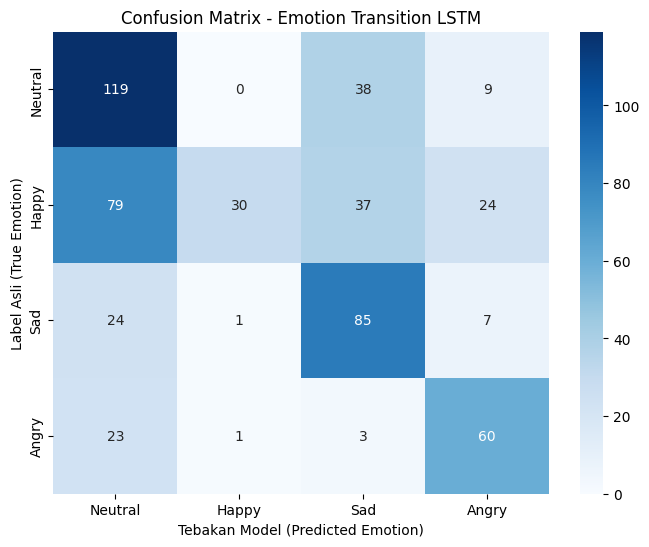

In [42]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Pindahkan model ke mode evaluasi
model.eval()

all_preds = []
all_trues = []

print("Memulai pengujian pada Test Set yang belum pernah dilihat model...")

with torch.no_grad():
    for batch_X, batch_y, batch_mask in test_loader:
        batch_X, batch_y, batch_mask = batch_X.to(device), batch_y.to(device), batch_mask.to(device)
        
        # Dapatkan raw output (logits)
        logits = model(batch_X) # Shape: (B, S, 4)
        
        # Ambil probabilitas tertinggi sebagai tebakan final
        preds = torch.argmax(logits, dim=-1) # Shape: (B, S)
        
        # Flatten (ratakan) tensor untuk perhitungan metrik
        preds_flat = preds.view(-1)
        y_flat = batch_y.view(-1)
        mask_flat = batch_mask.view(-1)
        
        # MASKING SANGAT PENTING: Kita harus membuang tebakan pada padding (angka 0)
        valid_preds = preds_flat[mask_flat].cpu().numpy()
        valid_trues = y_flat[mask_flat].cpu().numpy()
        
        all_preds.extend(valid_preds)
        all_trues.extend(valid_trues)

# Nama kelas sesuai dengan encoding kita sebelumnya: 
# 0: Neutral, 1: Happy, 2: Sad, 3: Angry
target_names = ["Neutral", "Happy", "Sad", "Angry"]

print("\n--- HASIL EVALUASI (CLASSIFICATION REPORT) ---")
# Ini akan otomatis menghitung Precision, Recall, dan F1-Score
print(classification_report(all_trues, all_preds, target_names=target_names, zero_division=0))

# --- MEMBUAT CONFUSION MATRIX ---
cm = confusion_matrix(all_trues, all_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=target_names, yticklabels=target_names)
plt.title('Confusion Matrix - Emotion Transition LSTM')
plt.ylabel('Label Asli (True Emotion)')
plt.xlabel('Tebakan Model (Predicted Emotion)')
plt.show()

In [43]:
import torch.nn.functional as F
import numpy as np
from sklearn.metrics import classification_report

model.eval()
all_trues = []
all_preds = []
all_entropies = []

print("Menghitung Shannon Entropy untuk setiap prediksi di Test Set...")

with torch.no_grad():
    for batch_X, batch_y, batch_mask in test_loader:
        batch_X, batch_y, batch_mask = batch_X.to(device), batch_y.to(device), batch_mask.to(device)
        
        logits = model(batch_X) 
        probs = F.softmax(logits, dim=-1) # Ubah ke probabilitas
        
        # Hitung Entropy H(P) = -sum(p * log(p))
        entropy = -torch.sum(probs * torch.log(probs + 1e-9), dim=-1)
        preds = torch.argmax(logits, dim=-1)
        
        # Flatten & Masking (buang padding)
        mask_flat = batch_mask.view(-1)
        valid_preds = preds.view(-1)[mask_flat].cpu().numpy()
        valid_trues = batch_y.view(-1)[mask_flat].cpu().numpy()
        valid_entropies = entropy.view(-1)[mask_flat].cpu().numpy()
        
        all_preds.extend(valid_preds)
        all_trues.extend(valid_trues)
        all_entropies.extend(valid_entropies)

all_preds = np.array(all_preds)
all_trues = np.array(all_trues)
all_entropies = np.array(all_entropies)

# --- SIMULASI SHANNON ENTROPY GATE ---
# Anda bisa bereksperimen mengubah nilai TAU di rentang 0.5 hingga 1.2
TAU = 0.8 

# Filter: Kita HANYA mengambil data yang model yakini (Entropy <= TAU)
confident_mask = all_entropies <= TAU

confident_preds = all_preds[confident_mask]
confident_trues = all_trues[confident_mask]

abstain_count = len(all_preds) - len(confident_preds)
abstain_rate = (abstain_count / len(all_preds)) * 100

print(f"\n--- HASIL SETELAH ENTROPY GATE (Ambang Batas Tau = {TAU}) ---")
print(f"Total Data Percakapan : {len(all_preds)} giliran bicara")
print(f"Model Abstain / Ragu  : {abstain_count} ({abstain_rate:.1f}% dibuang)")
print(f"Prediksi Confident    : {len(confident_preds)} diproses ke TTS\n")

print("--- CLASSIFICATION REPORT (HANYA PADA DATA CONFIDENT) ---")
print(classification_report(confident_trues, confident_preds, target_names=target_names, zero_division=0))

Menghitung Shannon Entropy untuk setiap prediksi di Test Set...

--- HASIL SETELAH ENTROPY GATE (Ambang Batas Tau = 0.8) ---
Total Data Percakapan : 540 giliran bicara
Model Abstain / Ragu  : 397 (73.5% dibuang)
Prediksi Confident    : 143 diproses ke TTS

--- CLASSIFICATION REPORT (HANYA PADA DATA CONFIDENT) ---
              precision    recall  f1-score   support

     Neutral       0.74      0.81      0.78        32
       Happy       1.00      0.19      0.33        36
         Sad       0.65      0.93      0.76        40
       Angry       0.77      0.97      0.86        35

    accuracy                           0.73       143
   macro avg       0.79      0.73      0.68       143
weighted avg       0.79      0.73      0.68       143

